In [5]:
from typing import List, TypedDict
import time
import os

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import GoogleGenerativeAIEmbeddings

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
load_dotenv()

True

In [8]:
doc = PyPDFLoader("./data/book1.pdf").load()
len(doc)

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(25, 0, 2180380689104), '/LastChar': 1, '/Widths': [833], '/BaseFont': '/NJBOIP+MathematicalPi-Three', '/FirstChar': 1, '/Encoding': IndirectObject(26, 0, 2180380689104), '/Type': '/Font'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(743, 0, 2180380689104), '/LastChar': 2, '/Widths': [778, 778], '/BaseFont': '/NJDFHF+MSAM10', '/FirstChar': 1, '/Encoding': IndirectObject(744, 0, 2180380689104), '/Type': '/Font'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(743, 0, 2180380

758

In [9]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(doc)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [21]:
len(chunks)

2467

In [6]:
# embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
)

to prevent free api exhaust this large code except just = vector_store = (chunks, embeddings)

In [41]:
import os
import time
from langchain_community.vectorstores import FAISS

INDEX_PATH = "faiss_index"

# 1. Load from disk if already created, so you don't burn daily quota
if os.path.exists(INDEX_PATH):
    print("Loading existing FAISS index from disk...")
    vector_store = FAISS.load_local(INDEX_PATH, embeddings, allow_dangerous_deserialization=True)
    print("Vector store loaded successfully!")
else:
    print(f"Creating vector store for {len(chunks)} chunks...")
    BATCH_SIZE = 60     # ~41 batches for 2467 chunks
    SLEEP_DELAY = 5.0   # 5 seconds pause = 12 requests/min (well within 15 RPM limit)

    vector_store = None

    for i in range(0, len(chunks), BATCH_SIZE):
        batch = chunks[i : i + BATCH_SIZE]
        batch_num = (i // BATCH_SIZE) + 1
        total_batches = (len(chunks) + BATCH_SIZE - 1) // BATCH_SIZE
        print(f"Processing batch {batch_num}/{total_batches} ({len(batch)} chunks)...")

        # Retry loop with backoff if rate limits are hit
        for attempt in range(5):
            try:
                if vector_store is None:
                    vector_store = FAISS.from_documents(batch, embeddings)
                else:
                    vector_store.add_documents(batch)
                break
            except Exception as e:
                print(f"  Attempt {attempt + 1} failed: {e}. Retrying in 20 seconds...")
                time.sleep(20)

        # Rate-limiting pause between batches
        time.sleep(SLEEP_DELAY)

    # 2. Save locally so it's cached permanently
    vector_store.save_local(INDEX_PATH)
    print("Finished! FAISS index saved to disk.")


Creating vector store for 2467 chunks...
Processing batch 1/42 (60 chunks)...
Processing batch 2/42 (60 chunks)...
  Attempt 1 failed: Error embedding content (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/embed_content_free_tier_requests, limit: 100, model: gemini-embedding-1.0\nPlease retry in 52.14325997s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/embe

KeyboardInterrupt: 

In [10]:
vector_store = FAISS.from_documents(chunks, embeddings)

In [11]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [37]:

llm = ChatOpenAI(
    # model="nvidia/nemotron-3.5-lightning:free",  # or any other OpenRouter model e.g. "google/gemini-2.0-flash-001"
    model="openai/gpt-6-luna",
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
    temperature=0.3,
)


In [15]:
contexts = retriever.invoke("heii")

In [20]:
class state(TypedDict):
    question : str
    docs : list[Document]
    answer : str

In [69]:
def retrieve(state):
    q = state["question"]
    return {"docs" : retriever.invoke(q)}

In [70]:
state1 = state(question="what is transformer")
retrieved = retrieve(state1)
state1["docs"] = retrieved["docs"]

In [24]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

In [38]:
chain = prompt | llm

ans = chain.invoke({"question": "what is 4", "context":"america is 4 as per now"})

In [65]:
def generate(state):
    context = "/n/n".join(d.page_content for d in state["docs"])
    chain = prompt | llm
    response = chain.invoke({"question": state["question"], "context":context})
    # print(response)

    return {"answer": response.content}

In [67]:
# state1["docs"]
state1["answer"] = generate(state1)
state1

{'question': 'what is transformer',
 'docs': [Document(id='3b95b022-f9e6-4821-a559-b34def956be8', metadata={'producer': 'Acrobat Distiller 6.0 (Windows)', 'creator': 'Adobe Acrobat 6.0', 'creationdate': '2006-10-18T12:52:36+08:00', 'author': 'Christopher M. Bishop', 'moddate': '2008-02-08T16:41:33+01:00', 'title': 'Pattern Recognition and Machine Learning', 'source': './data/book1.pdf', 'total_pages': 758, 'page': 282, 'page_label': '263'}, page_content='showing the effect of a continuous transforma-\ntion on a particular input vector xn. A one-\ndimensional transformation, parameterized by\nthe continuous variableξ, applied toxn causes\nit to sweep out a one-dimensional manifoldM.\nLocally, the effect of the transformation can be\napproximated by the tangent vector τn.\nx1\nx2\nxn\nτn\nξ\nM'),
  Document(id='473b2a1f-b852-4be2-be62-0f06ce0903e0', metadata={'producer': 'Acrobat Distiller 6.0 (Windows)', 'creator': 'Adobe Acrobat 6.0', 'creationdate': '2006-10-18T12:52:36+08:00', 'autho

In [77]:
graph = StateGraph(state)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)

graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

app = graph.compile()

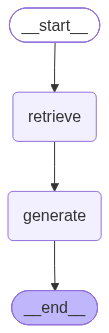

In [78]:
app

In [79]:
res = app.invoke({"question": "WHat is a transformer in deep learning.", "docs": [], "answer": ""})
print(res["answer"])

The context doesn’t explain what a transformer is, so I don’t know based on the provided information.
